# Introducción:

En este trabajo se utilizará una base de datos sintética extraída de [Kaggle](https://www.kaggle.com/), que contiene información sobre intentos de ciberataques. Con ella intentaremos conocer y analizar estos ataques, por ejemplo, como y donde se llevan a cabo, que particularidades tienen, que patrones existen, entre otras cosas. Y también observarlo desde al lugar de la víctima, sobre como reacciona o como le afecta. Para ello, se aplicarán medidas de resumen, tablas, gráficos, y entrenaremos algunos modelos de machine learning para predecir diferentes aspectos de estos ataques.

La ciberseguridad es un tema muy importante, delicado, el cual se debe conocer y enfatizar para evitar inconvenientes que pueden ser graves, y por ello es un tema intereseante de investigar. Aunque siempre teniendo claro que el objetivo principal es explorar, analizar datos, aplicar técnicas estadísticas.

In [86]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("Enterprise_Cyber_Kill_Chain_Dataset.csv")

# Datos:

Como se mencionó en la introducción, el dataset fue creado artificialmente de manera realista, sin ningún tipo de información personal.

Contiene toda la información de cada ataque, desde el primer momento en que se intenta hasta las consecuencias finales en la víctima.

Principal información del dataframe:

In [125]:
print("Filas:", df.shape[0])
print("Columnas:", df.shape[1])
print("Tipos de columnas:")
print(df.dtypes.value_counts().to_string())
print("Cantidad de ataques ('Incident_ID'):", df["Incident_ID"].nunique())

Filas: 100000
Columnas: 50
Tipos de columnas:
int64      25
str        14
float64    11
Cantidad de ataques ('Incident_ID'): 100000


Eliminanos las filas duplicadas:

In [88]:
df = df.drop_duplicates()

print("Columnas:", df.shape[0])
print("Cantidad de ataques ('Incident_ID'):", df["Incident_ID"].nunique())


Columnas: 100000
Cantidad de ataques ('Incident_ID'): 100000


In [135]:
print("Cantidad de datos faltantes por columna:")
print(df.isna().sum().sort_values(ascending = False).head(6).to_string())
print("...                       0")


Cantidad de datos faltantes por columna:
Recovery_Cost_USD     70594
Compliance            42772
Financial_Loss_USD     5006
Detection_Time_Min     3147
Company_Size              0
Employee_Count            0
...                       0


Entonces tenemos una base de datos con 100000 ataques diferentes y 50 variables que caracterizan cada uno de ellos. De estas 50, tenemos 25 númericas discretas, 11 continuas y 14 cualitativas. Debemos tener en cuenta que algunas de las 25 discretas, son binarias, que valen 1 si la observación cumple con esa variable, y 0 en caso contrario.

Las variables de respuesta o interés de este analisis son: `Attack_Success` que indica si el ataque tuvo éxito o no, y `Cyber_Risk_Score` que numera del 1 al 100 cada ataque según su nivel de riesgo.

<positron-console-cell-90>:4: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.


Text(0, 0.5, 'Cantidad de ataques')

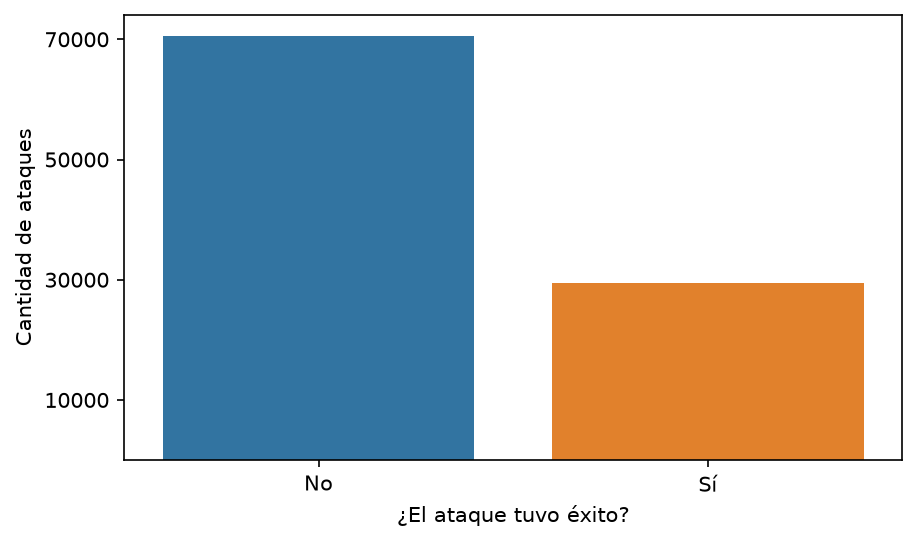

In [ ]:
fig, ax = plt.subplots(figsize=(5.75, 3.5), layout="constrained")
sns.countplot(data = df, x = "Attack_Success", hue = "Attack_Success", ax=ax)
ax.legend().remove()
ax.set_xticklabels(["No", "Sí"])
ax.set_yticks([10000,30000,50000,70000])
ax.set_xlabel("¿El ataque tuvo éxito?")
ax.set_ylabel("Cantidad de ataques")


Vemos que de todos los ataques, 70000, que equivale al 70%, fracasó y 30% restante efectivamente tuvo éxito. Estas cantidad exactas están claramente asociadas a la sintecidad de los datos. En datos reales, es muy poco probable que existan estos porcentajes enteros.

In [136]:
df["Cyber_Risk_Score"].describe()

count    100000.000000
mean         45.005120
std          19.047731
min           1.337935
25%          30.387444
50%          41.635008
75%          57.437351
max         100.000000
Name: Cyber_Risk_Score, dtype: float64

Text(0, 0.5, 'Cantidad')

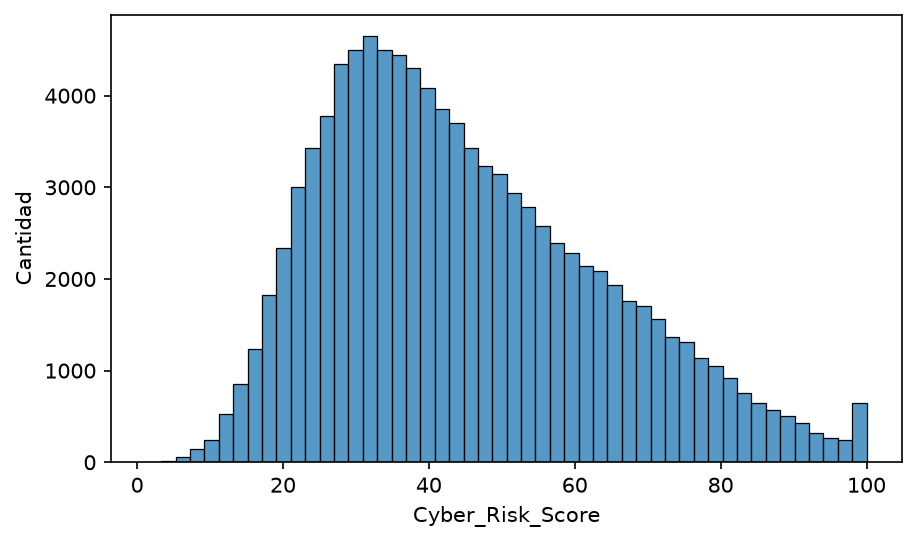

In [ ]:
fig, ax = plt.subplots(figsize=(5.75, 3.5), layout="constrained")
sns.histplot(data=df, x="Cyber_Risk_Score", ax=ax, fill = True, bins = 50)
ax.set_ylabel("Cantidad")


<Axes: xlabel='Cyber_Risk_Score', ylabel='Density'>

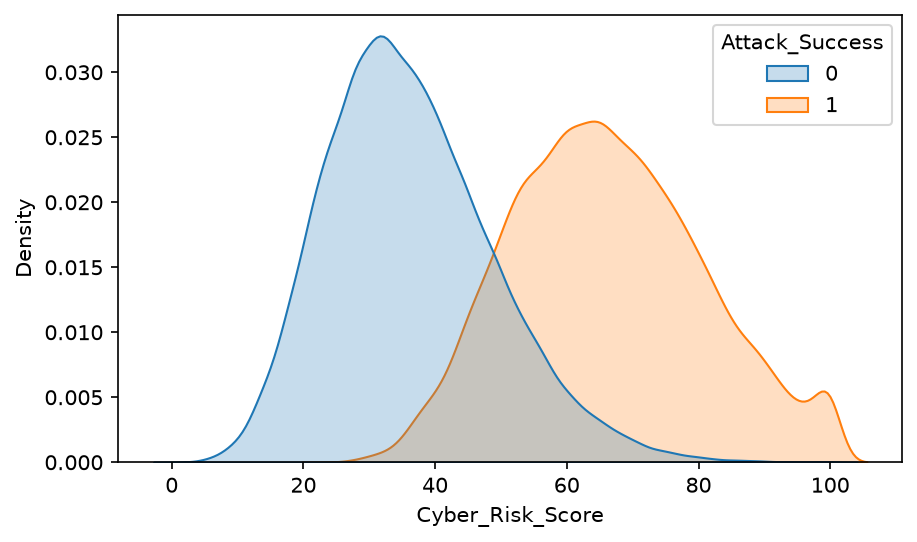

In [ ]:
fig, ax = plt.subplots(figsize=(5.75, 3.5), layout="constrained")
sns.kdeplot(data=df,
 x = "Cyber_Risk_Score",hue = "Attack_Success", ax=ax, fill = True, common_norm = False)

EL nivel de riesgo del ataque observamos que tiene una distribución, con media 45 y asimetría a la derecha, donde el tercer percentil es 57.4 y el máximo 100. Destacando el último intevalo que rompe con el patrón, y tiene bastante observaciones relativamente.

Text(0.5, 0, 'Cantidad')

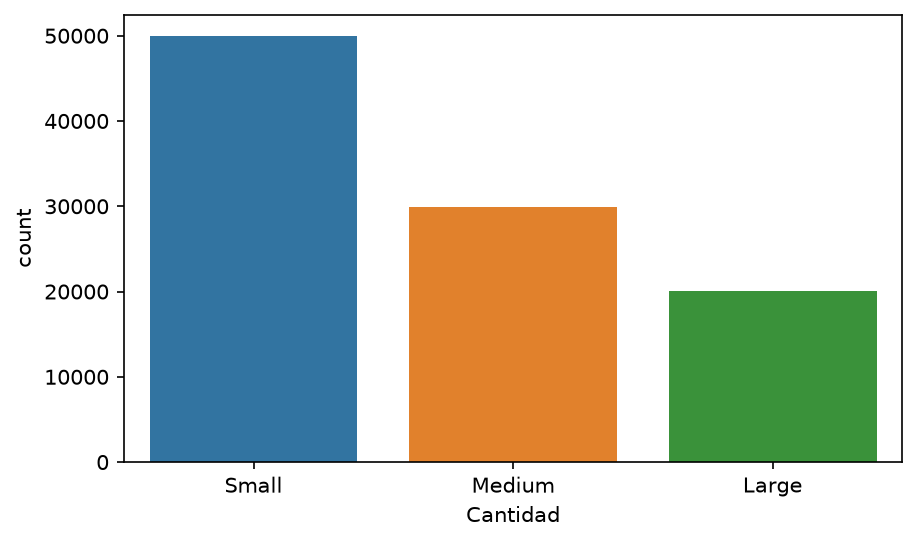

In [ ]:
fig, ax = plt.subplots(figsize=(5.75, 3.5), layout="constrained")
sns.countplot(data = df, x = "Company_Size", hue = "Company_Size", ax=ax)
ax.set_xlabel("Cantidad")

<Axes: xlabel='Security_Audit_Score', ylabel='Density'>

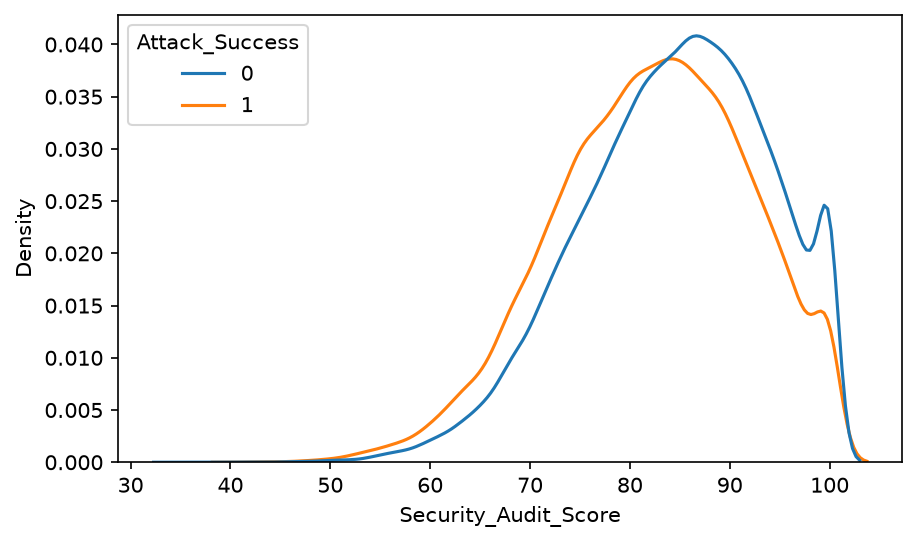

In [ ]:
fig, ax = plt.subplots(figsize=(5.75, 3.5), layout="constrained")
sns.kdeplot(data = df, x = "Security_Audit_Score", hue = "Attack_Success", common_norm=False, ax=ax)

<Axes: xlabel='Detection_Time_Min', ylabel='Response_Time_Min'>

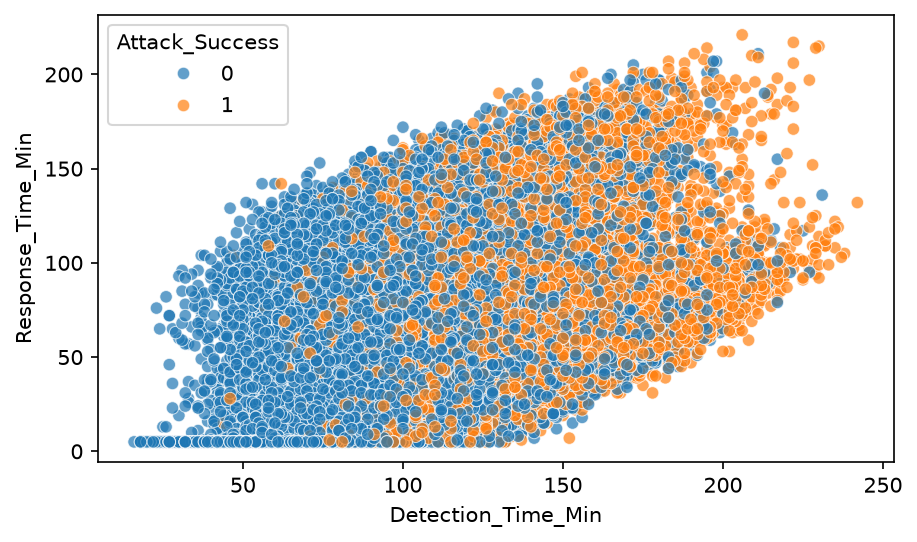

In [ ]:
fig, ax = plt.subplots(figsize=(5.75, 3.5), layout="constrained")
sns.scatterplot(data = df,
 y = "Response_Time_Min",
 x = "Detection_Time_Min", hue = "Attack_Success", ax=ax, alpha = 0.7)

In [174]:
df["perc_SOC"] = 100*df["SOC_Team_Size"] / df["Employee_Count"]
df["cat_SOC"] = df['perc_SOC'].case_when(caselist=[
    (df["perc_SOC"] <= df["perc_SOC"].quantile(0.25), "Bajo"),
    (df["perc_SOC"] <= df["perc_SOC"].quantile(0.50), "Medio"),
    (df["perc_SOC"] <= df["perc_SOC"].quantile(0.75), "Alto"),
    (df["perc_SOC"] > df["perc_SOC"].quantile(0.75), "Muy Alto")
])

(df
.groupby('cat_SOC')
.agg(total_casos = ('Attack_Success', 'size'),
    cant_exitos = ('Attack_Success', 'sum'))
.assign(prop = lambda x: x['cant_exitos'] / x['total_casos'])
.loc[["Bajo", "Medio", "Alto", "Muy Alto"]]
)

,total_casos,cant_exitos,prop
cat_SOC,,,
Bajo,25036,7395,0.295375
Medio,25046,7334,0.292821
Alto,24943,7394,0.296436
Muy Alto,24975,7283,0.291612


## MODELOS DE PREDICCIÓN

DOS MODELOS:

1- Clasificación: Predecir si el ataque tuvo éxito `Attack_Success`

2- Regresión: Predecir el nivel de riesgo del ataque `Cyber_Risk_Score`

1 - Para clasificar la variable `Attack_Success` realizaremos un árbol de decisión.

De las 50 variables, muchas caracterizan las consecuencias del ataque o como fue el ataque en sí. Por ende, si nuestro modelo quiere predecir si un ataque tuvo éxito o no, podríamos usar este tipo de variable, pero lo interesante sería intentar predecir, si un ataque va a tener éxito o no, analizando las caracteristicas de la empresa, antes de que un ataque suceda. Es decir, si queremos saber si un ataque tuvo éxito, y miramos la variable que mide la pérdidas económicas por el ataque, está claro que si el valor es alto, el ataque sucedió. Entonces las variables que vamos a usar, son aquellas que caracterizan a la empresa, en aspectos generales y en tanto a la defensa ante ataques. Asumimos que el ataque 'va a suceder' pero no sabemos como, y queremos predecir que tan factible es que suceda.

In [99]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

# variables que describen a la empresa
desc_empresa = ["Industry", "Country", "Company_Size", "Employee_Count",
          "Firewall", "MFA", "EDR", "IDS", "Security_Training", "Password_Policy",
          "Security_Maturity", "SOC_Team_Size", "Security_Audit_Score", "Compliance",
          "CVSS_Score", "Patch_Age_Days", "Open_Vulnerabilities", "Internet_Exposed",
          "Vendor_Count", "ThirdParty_Risk", "Insider_Risk"]

X_tree = pd.get_dummies(df[desc_empresa])

y_tree = df["Attack_Success"]
X_tree_train, X_tree_test, y_tree_train, y_tree_test = train_test_split(
X_tree, y_tree, test_size=0.25, random_state=123, stratify=y_tree
)

arbol = DecisionTreeClassifier(max_depth= 5, random_state= 123)
arbol.fit(X_tree_train, y_tree_train)
arbol.get_params()


{'ccp_alpha': 0.0,
 'class_weight': None,
 'criterion': 'gini',
 'max_depth': 5,
 'max_features': None,
 'max_leaf_nodes': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 1,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'random_state': 123,
 'splitter': 'best'}

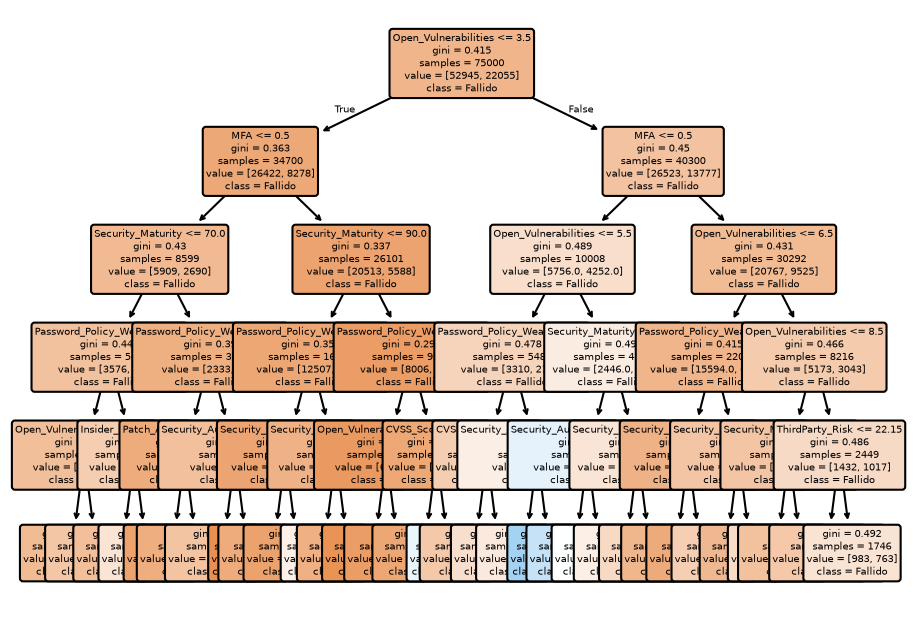

In [ ]:
from sklearn.tree import plot_tree

fig, ax = plt.subplots(figsize=(5.75, 4.5), layout="constrained")
plot_tree(arbol, feature_names=X_tree.columns, class_names=["Fallido", "Exitoso"],
           filled=True, rounded=True, fontsize = 5,ax=ax)
plt.show()

In [ ]:
from sklearn.metrics import confusion_matrix

confusion_matrix(y_tree_test, arbol.predict(X_tree_test))

array([[17477,   172],
       [ 7189,   162]])

In [102]:
from sklearn.metrics import classification_report

print(classification_report(y_tree_test, arbol.predict(X_tree_test)))

              precision    recall  f1-score   support

           0       0.71      0.99      0.83     17649
           1       0.49      0.02      0.04      7351

    accuracy                           0.71     25000
   macro avg       0.60      0.51      0.43     25000
weighted avg       0.64      0.71      0.60     25000



En la misma línea que el árbol, para predecir el nivel de riesgo de un ataque, mediante un random forest, no utilizaremos todas las variables.
Primero definamos a que se refiere la variable con nivel de riesgo. Lo vamos a definir como que tan probable es que 

In [103]:
from sklearn.model_selection import train_test_split

# variables que describen el inicio del ataque
desc_ataque = ["Attack_Vector", "Threat_Actor", "Attack_Complexity", "Zero_Day",
          "Hour", "DayOfWeek", "Month", "Business_Hours", "Weekend", "Phishing_Click"]

X_rf = pd.get_dummies(df[desc_empresa + desc_ataque])
y_rf = df["Cyber_Risk_Score"]

X_rf_train, X_rf_test, y_rf_train, y_rf_test = train_test_split(
X_rf, y_rf, test_size=0.25, random_state=123
)

In [105]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV

grilla = GridSearchCV(
    RandomForestRegressor(n_estimators=100, random_state=123),
    param_grid={"max_depth": [5, 10, None],
                "max_features": [0.2, 0.5, 1.0]},
    cv=4,
    n_jobs = -1
)

grilla.fit(X_rf_train, y_rf_train)
grilla.best_params_, grilla.best_score_.round(3)

({'max_depth': 10, 'max_features': 0.5}, np.float64(0.546))

In [106]:
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

rf = RandomForestRegressor(n_estimators = 250, max_depth= 10, max_features = 0.5, random_state=123)
rf.fit(X_rf_train, y_rf_train)

pd.Series({
"MAE": mean_absolute_error(y_rf_test, rf.predict(X_rf_test)),
"RMSE": root_mean_squared_error(y_rf_test, rf.predict(X_rf_test)),
"R2": r2_score(y_rf_test, rf.predict(X_rf_test)),
}).round(2)

MAE     10.69
RMSE    12.70
R2       0.55
dtype: float64

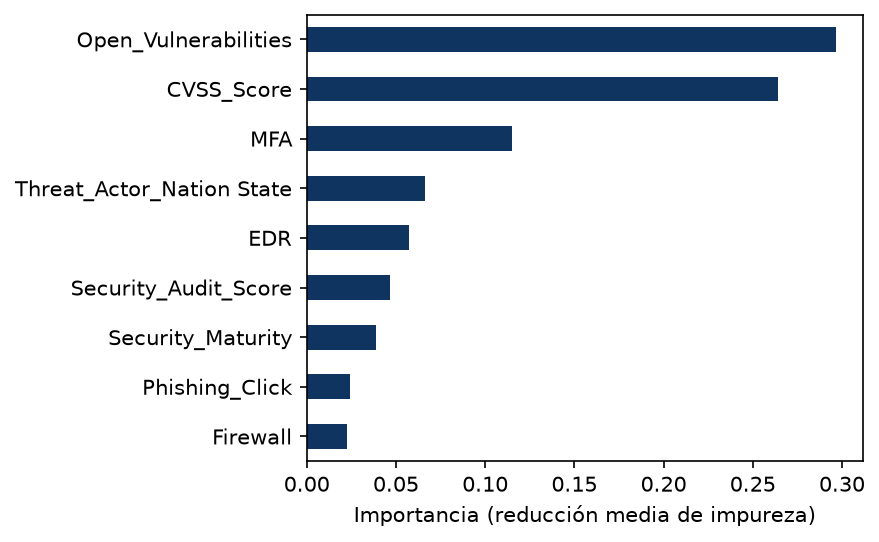

In [110]:
importancias = pd.Series(rf.feature_importances_, index=X_rf.columns).sort_values()
importancias = importancias[importancias > 0.01]

fig, ax = plt.subplots(figsize=(5.75, 3.5), layout="constrained")
importancias.plot.barh(color="#0f3460", ax=ax)
ax.set(xlabel="Importancia (reducción media de impureza)", ylabel="")
plt.show()